# ytviews walkthrough

A tour of the view-count predictor, end to end, on the built-in **synthetic** dataset (so it runs offline, without a YouTube API key). The numbers show the machinery working; they are not accuracy on real YouTube videos.

Steps: generate data → train and evaluate → predict → explain → compare titles → forecast a live video → pick a publish time.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ytviews.images import attach_thumbnails, thumbnail_dir_for
from ytviews.pipeline import run_experiment
from ytviews.predictor import Predictor, VideoInput
from ytviews.store import VideoStore
from ytviews.synthetic import write_synthetic_db
from ytviews.train import TrainConfig

work = Path(tempfile.mkdtemp())
pd.set_option('display.width', 120)

## 1. Data

The synthetic generator plants known effects (channel size and quality, title wording, thumbnail design, publish time, growth that differs per video) and stores videos exactly like the real YouTube collector does, including two snapshots per video.

In [2]:
db = work / 'synthetic.db'
print(write_synthetic_db(db, n_channels=80, seed=3))
with VideoStore(db) as store:
    df = store.load_dataset(all_snapshots=True)
df = attach_thumbnails(df, thumbnail_dir_for(db))
df[['title', 'category_id', 'subscribers', 'views', 'published_at', 'fetched_at']].head()

{'videos': 1795, 'snapshots': 3505, 'channels': 80}


,title,category_id,subscribers,views,published_at,fetched_at
0,Why Minecraft Is Insane,20,31558.0,16801.0,2025-10-22 01:05:00.019095+00:00,2026-09-10 01:00:04+00:00
1,Testing Viral Boss Hacks,20,31558.0,26579.0,2025-10-29 08:29:00.317635+00:00,2026-09-10 01:00:04+00:00
2,TESTING VIRAL SURVIVAL HACKS #shorts,20,31558.0,42462.0,2025-11-11 03:19:00.357063+00:00,2026-09-10 01:00:04+00:00
3,Survival Challenge (GONE WRONG),20,31558.0,41688.0,2025-11-25 16:55:00.998311+00:00,2026-09-10 01:00:04+00:00
4,Testing Viral Minecraft Hacks #shorts,20,31558.0,340994.0,2025-11-23 21:50:00.336545+00:00,2026-09-10 01:00:04+00:00


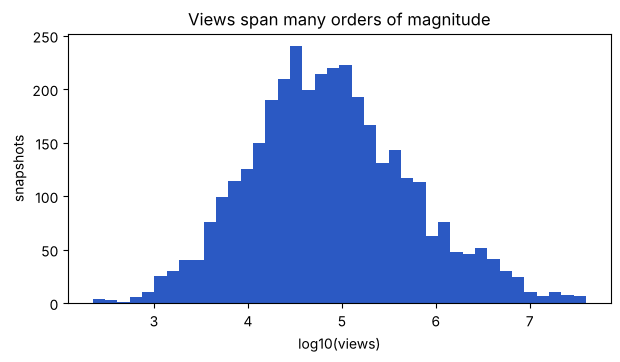

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(df['views'].clip(lower=1)), bins=40, color='#2b59c3')
ax.set(xlabel='log10(views)', ylabel='snapshots', title='Views span many orders of magnitude')
plt.show()

## 2. Train and evaluate

`run_experiment` splits by time (older uploads train, newest test), trains the network ensemble, picks a network/LightGBM blend on an inner split, compares against baselines and saves everything.

In [4]:
model_dir = work / 'model'
meta = run_experiment(df, model_dir, text_encoder='tfidf', image_encoder='stats',
                      config=TrainConfig(ensemble=2), log=lambda _: None)
metrics = pd.DataFrame(meta['metrics']).T[['mae_log', 'median_factor_error', 'within_2x', 'interval_coverage']]
metrics.sort_values('mae_log').round(3)

,mae_log,median_factor_error,within_2x,interval_coverage
ridge (all features),0.709,1.813,0.573,NaN
ytviews (ours),0.740,1.846,0.553,0.877
neural net only,0.776,2.028,0.488,0.873
lightgbm (all features),0.783,1.900,0.546,NaN
channel heuristic,0.879,2.130,0.471,NaN
global median,1.671,4.365,0.248,NaN


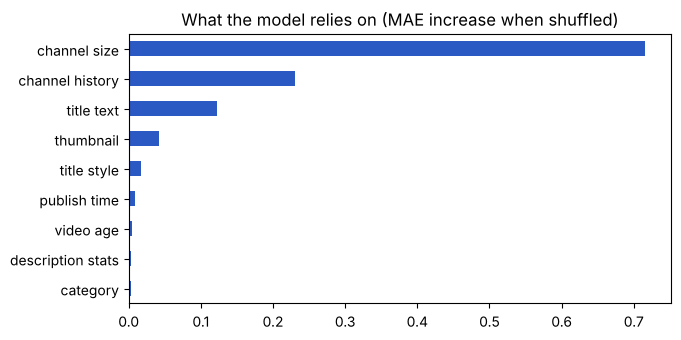

In [5]:
imp = pd.Series(meta['importance']).sort_values()
imp[imp > 0.001].plot.barh(figsize=(7, 3.5), color='#2b59c3',
    title='What the model relies on (MAE increase when shuffled)')
plt.show()

## 3. Predict a planned video

In [6]:
p = Predictor.load(model_dir)
video = VideoInput(title='I Survived 100 Days in Minecraft', category_id='20',
                   subscribers=250_000, duration_s=900,
                   recent_video_views=[180_000, 95_000, 240_000, 130_000])
pred = p.predict(video)[0]
print(f'7 days: ~{pred.median:,.0f} views (80% range {pred.low:,.0f} - {pred.high:,.0f})')

7 days: ~120,590 views (80% range 28,355 - 459,678)


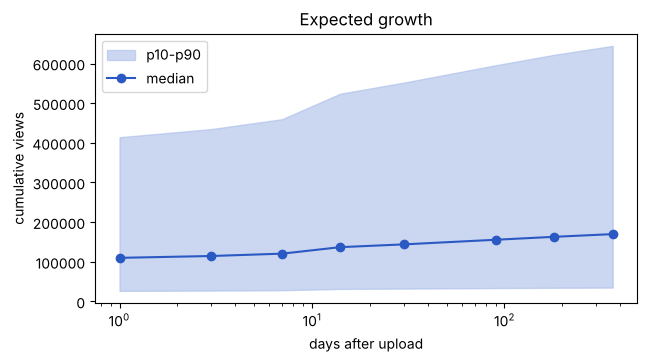

In [7]:
traj = p.trajectory(video)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.fill_between(traj['days'], traj['low'], traj['high'], color='#a9bde9', alpha=.6,
                label='p10-p90')
ax.plot(traj['days'], traj['median'], color='#2b59c3', marker='o', label='median')
ax.set(xscale='log', xlabel='days after upload', ylabel='cumulative views',
       title='Expected growth')
ax.legend()
plt.show()

## 4. Why that number?

Exact Shapley values over feature groups, relative to an average video of the same age. The factors multiply out to the prediction.

In [8]:
ex = p.explain(video)
print(f'average video: {ex.baseline_views:,.0f} -> this video: {ex.predicted_views:,.0f}')
ex.effects.round(3)

average video: 42,036 -> this video: 120,590


,group,log_effect,factor
0,title text,0.464,1.591
1,channel size,0.437,1.549
2,title style,0.271,1.312
3,channel history,0.211,1.235
4,description text,-0.190,0.827
5,description stats,-0.119,0.888
6,publish time,0.083,1.087
7,category,-0.080,0.923
8,format,-0.034,0.966
9,thumbnail,0.010,1.010


## 5. Which title?

In [9]:
titles = ['I Survived 100 Days in Minecraft', 'Minecraft Hardcore Ep. 12',
          '$1 vs $10,000 Minecraft Build', 'Weekly Minecraft Update']
p.compare_titles(video, titles).round(2)

,title,low,median,high,vs_best
0,I Survived 100 Days in Minecraft,28355.27,120590.13,459678.29,1.00
1,"$1 vs $10,000 Minecraft Build",25992.06,117654.29,398753.86,0.98
2,Minecraft Hardcore Ep. 12,12981.14,52435.09,208354.39,0.43
3,Weekly Minecraft Update,5121.28,21156.31,80155.77,0.18


In [10]:
from ytviews.suggest import suggest_titles
suggest_titles(p, VideoInput(title='Minecraft Hardcore Ep. 12', category_id='20',
                             subscribers=250_000)).head(6).round(2)

,title,source,low,median,high,vs_best
0,Testing Viral Minecraft Hardcore Hacks,rewrite,16323.53,80572.29,363152.41,1.00
1,"I Spent $1,000 on Minecraft Hardcore",rewrite,13757.15,76475.22,315832.05,0.95
2,I Tried Minecraft Hardcore for 30 Days,rewrite,12924.02,69427.97,324758.87,0.86
3,The Truth About Minecraft Hardcore,rewrite,11798.93,62046.65,312013.66,0.77
4,Minecraft Hardcore (I Didn't Expect This),rewrite,9792.73,52296.63,242397.57,0.65
5,Is Minecraft Hardcore Actually Worth It?,rewrite,9757.96,51623.63,240414.14,0.64


## 6. Already live: forecast from early views

How much an early lead or lag persists was calibrated on held-out videos that were fetched at two ages.

In [11]:
nc = p.track(video, observed_views=60_000, observed_age_days=1)
print(f'pace vs expectation: {nc.vs_expected:.2f}x (expected ~{nc.expected_views:,.0f} after 1 day)')
nc.forecast.round(0)

pace vs expectation: 0.55x (expected ~109,996 after 1 day)


,days,low,median,high
0,3,76280.0,94176.0,115441.0
1,7,80229.0,99052.0,121417.0
2,14,91098.0,112471.0,137866.0
3,30,95786.0,118258.0,144960.0
4,90,103528.0,127816.0,156677.0
5,180,108427.0,133865.0,164092.0
6,365,112981.0,139487.0,170983.0


## 7. When to publish

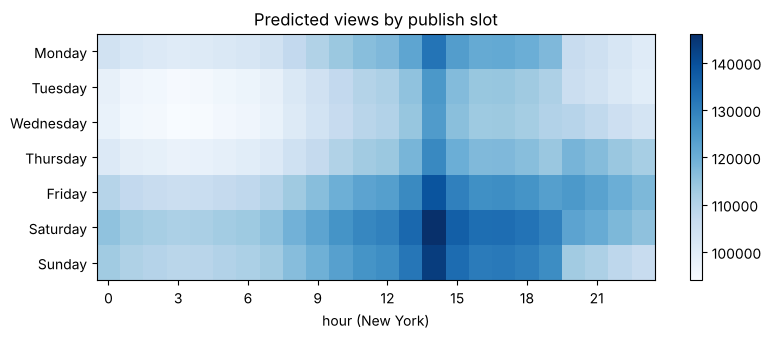

In [12]:
grid = p.publish_times(video, 'America/New_York')
heat = grid.pivot(index='weekday_index', columns='hour', values='median')
days = grid.drop_duplicates('weekday_index').set_index('weekday_index')['weekday']
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7), [days[i] for i in heat.index])
ax.set_xticks(range(0, 24, 3), range(0, 24, 3))
ax.set(xlabel='hour (New York)', title='Predicted views by publish slot')
fig.colorbar(im, ax=ax)
plt.show()

## Next: real data

```bash
cp .env.example .env          # add YOUTUBE_API_KEY
ytviews doctor --online
ytviews collect --seed-channels && ytviews thumbnails
ytviews tune && ytviews train --config best_config.json
ytviews report --html report.html
```